# Brief C · Money · Invoice–Payment Reconciliation
**Question:** *Which invoices were never paid, which payments match no invoice, and how much of the gap is only timing?*

**Pain Points:** Two id families | A gap nobody has sized | Revenue reported with an asterisk

**Data:** `invoices_2026Q1/Q2.csv`, `gateway_export_2026-03/04.csv`, `settlements_2026Q1/Q2.csv`

---
### Pipeline
1. Profile both exports (counts · dtypes · id formats · date ranges · duplicates)
2. Write the id mapping rule
3. Join with row counts
4. Classify every gap
5. Build the bridge waterfall chart
6. Export clean files for finance


In [7]:
pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
# Cell 01 · Imports & paths
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import re, warnings
from pathlib import Path

warnings.filterwarnings('ignore')

RAW = Path(r'E:\IITGN_Projects\Week_3\build1-starter-kit\data\raw')
OUT = Path(r'E:\IITGN_Projects\Week_3\build1-starter-kit\brief_c\data')
OUT.mkdir(parents=True, exist_ok=True)

PURPLE = '#7c3aed'; GREEN = '#22c55e'; RED = '#ef4444'
AMBER  = '#f59e0b'; TEAL  = '#14b8a6'; LGRAY = '#94a3b8'
BG     = '#0f0f1a'

print('Paths OK | pandas', pd.__version__, '| numpy', np.__version__)


Paths OK | pandas 2.2.3 | numpy 2.1.3


---
## Step 1 · Profile both exports
> *Done when you hold a profile of each and a written mapping rule.*

**Challenge logged ①** Amount column loads as `object` (thousand-separator commas).  
**Challenge logged ②** `amount_paise` is ×100 rupees — unit mismatch with invoices.


In [2]:
# Cell 02 · Load & profile invoices
inv_q1 = pd.read_csv(RAW/'invoices'/'invoices_2026Q1.csv',
                     parse_dates=['invoice_date'], thousands=',')
inv_q2 = pd.read_csv(RAW/'invoices'/'invoices_2026Q2.csv',
                     parse_dates=['invoice_date'], thousands=',')

for label, df in [('Q1', inv_q1), ('Q2', inv_q2)]:
    print(f'=== {label} invoices ===')
    print(f'  Rows  : {len(df):,}   Cols: {list(df.columns)}')
    print(f'  dtypes: {df.dtypes.to_dict()}')
    print(f'  id sample  : {df["invoice_id"].head(3).tolist()}')
    print(f'  date range : {df["invoice_date"].min()}  →  {df["invoice_date"].max()}')
    print(f'  amount range: Rs {df["amount"].min():,.2f}  →  Rs {df["amount"].max():,.2f}')
    print(f'  nulls :\n{df.isnull().sum().to_string()}')
    print()


=== Q1 invoices ===
  Rows  : 83,630   Cols: ['invoice_id', 'invoice_date', 'booking_id', 'patient_id', 'city', 'channel', 'amount']
  dtypes: {'invoice_id': dtype('O'), 'invoice_date': dtype('<M8[ns]'), 'booking_id': dtype('O'), 'patient_id': dtype('O'), 'city': dtype('O'), 'channel': dtype('O'), 'amount': dtype('float64')}
  id sample  : ['INV-2026-000001', 'INV-2026-000002', 'INV-2026-000003']
  date range : 2026-01-01 00:00:00  →  2026-03-31 00:00:00
  amount range: Rs 120.00  →  Rs 8,847.00
  nulls :
invoice_id      0
invoice_date    0
booking_id      0
patient_id      0
city            0
channel         0
amount          0

=== Q2 invoices ===
  Rows  : 79,246   Cols: ['invoice_id', 'invoice_date', 'booking_id', 'patient_id', 'city', 'channel', 'amount']
  dtypes: {'invoice_id': dtype('O'), 'invoice_date': dtype('<M8[ns]'), 'booking_id': dtype('O'), 'patient_id': dtype('O'), 'city': dtype('O'), 'channel': dtype('O'), 'amount': dtype('float64')}
  id sample  : ['INV-2026-083631', 

In [11]:
# Cell 03 · Load & profile payments + settlements
pay_q1 = pd.read_csv(RAW/'payments'/'gateway_export_2026-03.csv')
pay_q2 = pd.read_csv(RAW/'payments'/'gateway_export_2026-04.csv')
setl_q1 = pd.read_csv(RAW/'payments'/'settlements_2026Q1.csv')
setl_q2 = pd.read_csv(RAW/'payments'/'settlements_2026Q2.csv')

for label, df in [('Q1 gateway', pay_q1), ('Q2 gateway', pay_q2)]:
    print(f'=== {label} ===')
    print(f'  Rows  : {len(df):,}')
    print(f'  Status: {df["status"].value_counts().to_dict()}')
    print(f'  pay_id sample : {df["payment_id"].head(3).tolist()}')
    print(f'  inv_ref sample: {df["notes_invoice_ref"].head(3).tolist()}')
    print(f'  amount paise  : {df["amount_paise"].min():,} – {df["amount_paise"].max():,}')
    print(f'  amount rupees : Rs {df["amount_paise"].min()/100:,.2f} – Rs {df["amount_paise"].max()/100:,.2f}')
    print(f'  nulls:\n{df.isnull().sum().to_string()}')
    print()

for label, df in [('Q1 settlements', setl_q1), ('Q2 settlements', setl_q2)]:
    print(f'=== {label} === rows={len(df)}')
    print(df.to_string(index=False))
    print(f'  settled Rs: {df["amount_paise"].sum()/100:>16,.2f}  fees Rs: {df["fees_paise"].sum()/100:>12,.2f}')
    print()


=== Q1 gateway ===
  Rows  : 28,147
  Status: {'captured': 27073, 'failed': 1074}
  pay_id sample : ['pay_000005697f', 'pay_0000056987', 'pay_0000056988']
  inv_ref sample: ['INV-2026-041979', 'INV-2026-041987', 'INV-2026-041988']
  amount paise  : 12,000 – 869,700
  amount rupees : Rs 120.00 – Rs 8,697.00
  nulls:
payment_id              0
notes_invoice_ref       0
amount_paise            0
status                  0
created_at_epoch        0
method                  0
settlement_id        1074

=== Q2 gateway ===
  Rows  : 27,094
  Status: {'captured': 26053, 'failed': 1041}
  pay_id sample : ['pay_000005dd52', 'pay_000005dd53', 'pay_000005dd6e']
  inv_ref sample: ['INV2026071258', 'INV2026071258', 'INV-2026-071284']
  amount paise  : 12,000 – 914,700
  amount rupees : Rs 120.00 – Rs 9,147.00
  nulls:
payment_id              0
notes_invoice_ref       0
amount_paise            0
status                  0
created_at_epoch        0
method                  0
settlement_id        1041

=== 

---
## Step 2 · Write the id mapping rule

**Challenge logged ③** Q1 refs: `INV-2026-XXXXXX` (hyphens).  Q2 refs: `INV2026XXXXXX` (no hyphens).  
**Decision #4:** Strip all non-digit characters; match on full numeric string.


In [12]:
# Cell 04 · Normalise invoice id mapping rule
import re

def normalise_inv_ref(ref):
    """Strip non-digit chars; return numeric string.
    INV-2026-000001 -> '2026000001'
    INV2026071258   -> '2026071258'
    """
    if pd.isna(ref): return np.nan
    return re.sub(r'[^0-9]', '', str(ref))

# Validate
tests = [
    ('INV-2026-000001', '2026000001'),
    ('INV-2026-041979', '2026041979'),
    ('INV2026071258',   '2026071258'),
    (np.nan,            np.nan),
]
print('Mapping rule validation:')
for inp, expected in tests:
    result = normalise_inv_ref(inp)
    ok = (result == expected) or (pd.isna(result) and pd.isna(expected))
    print(f'  {str(inp):28s} -> {str(result):14s}  [{ "OK" if ok else "FAIL" }]')
print()
print('Rule: strip all non-digit characters, match on full numeric string.')


Mapping rule validation:
  INV-2026-000001              -> 2026000001      [OK]
  INV-2026-041979              -> 2026041979      [OK]
  INV2026071258                -> 2026071258      [OK]
  nan                          -> nan             [OK]

Rule: strip all non-digit characters, match on full numeric string.


---
## Step 1b · Clean both tables
**Decisions #1–#8 from decisions-log applied here.**


In [30]:
# Cell 05 · Clean invoices (combine, dedup, normalise key)
inv_raw = pd.concat([inv_q1.assign(quarter='Q1'), inv_q2.assign(quarter='Q2')], ignore_index=True)
print(f'Combined invoices (raw):  {len(inv_raw):,}')

# Drop null invoice_id
null_inv = inv_raw['invoice_id'].isna().sum()
inv_clean = inv_raw.dropna(subset=['invoice_id']).copy()
print(f'Dropped null invoice_id : {null_inv}')

# Drop exact duplicate invoice_id (keep first); log rejected
inv_dups = inv_clean[inv_clean.duplicated(subset='invoice_id', keep=False)].copy()
dup_inv  = inv_clean.duplicated(subset='invoice_id', keep='first').sum()
inv_clean = inv_clean.drop_duplicates(subset='invoice_id', keep='first').copy()
print(f'Duplicate invoice_id dropped: {dup_inv}')

# Normalise key
inv_clean['inv_key'] = inv_clean['invoice_id'].apply(normalise_inv_ref)

# Fill null city
inv_clean['city'] = inv_clean['city'].fillna('unknown')

print(f'Clean invoices (final):   {len(inv_clean):,}')
print(f'Total invoiced (Rs):      {inv_clean["amount"].sum():>16,.2f}')
inv_clean[['invoice_id','invoice_date','amount','city','channel','quarter','inv_key']].head(3)


Combined invoices (raw):  162,876
Dropped null invoice_id : 0
Duplicate invoice_id dropped: 0
Clean invoices (final):   162,876
Total invoiced (Rs):        268,283,173.00


,invoice_id,invoice_date,amount,city,channel,quarter,inv_key
0,INV-2026-000001,2026-01-01,1499.0,Ahmedabad,clinic,Q1,2026000001
1,INV-2026-000002,2026-01-01,750.0,Pune,home,Q1,2026000002
2,INV-2026-000003,2026-01-01,2000.0,Ahmedabad,home,Q1,2026000003


In [28]:
# Cell 06 · Clean payments (combine, captured-only, paise->Rs, normalise key)
pay_raw = pd.concat([pay_q1.assign(quarter='Q1'), pay_q2.assign(quarter='Q2')], ignore_index=True)
print(f'Combined payments (raw):  {len(pay_raw):,}')
print('Status (raw):', pay_raw['status'].value_counts().to_dict())

# Decision #7: epoch -> datetime
pay_raw['paid_at'] = pd.to_datetime(pay_raw['created_at_epoch'], unit='s', utc=True).dt.tz_convert('Asia/Kolkata')

# Decision #3: captured only
pay_rejected = pay_raw[pay_raw['status'] != 'captured'].copy()
pay_captured = pay_raw[pay_raw['status'] == 'captured'].copy()
print(f'Rejected (non-captured):  {len(pay_rejected):,}  -> {pay_rejected["status"].value_counts().to_dict()}')

# Drop null payment_id
null_pay = pay_captured['payment_id'].isna().sum()
pay_captured = pay_captured.dropna(subset=['payment_id'])
print(f'Dropped null payment_id : {null_pay}')

# Decision #6: dedup payment_id
pay_dups = pay_captured[pay_captured.duplicated(subset='payment_id', keep=False)].copy()
dup_pay  = pay_captured.duplicated(subset='payment_id', keep='first').sum()
pay_captured = pay_captured.drop_duplicates(subset='payment_id', keep='first').copy()
print(f'Duplicate payment_id dropped: {dup_pay}')

# Decision #2: paise -> rupees
pay_captured['amount_rs'] = pay_captured['amount_paise'] / 100

# Decision #4: normalise key
pay_captured['inv_key'] = pay_captured['notes_invoice_ref'].apply(normalise_inv_ref)

print(f'Captured payments (final): {len(pay_captured):,}')
print(f'Total collected (Rs):      {pay_captured["amount_rs"].sum():>16,.2f}')
pay_captured[['payment_id','inv_key','amount_rs','method','paid_at','quarter']].head(3)


Combined payments (raw):  55,241
Status (raw): {'captured': 53126, 'failed': 2115}
Rejected (non-captured):  2,115  -> {'failed': 2115}
Dropped null payment_id : 0
Duplicate payment_id dropped: 0
Captured payments (final): 53,126
Total collected (Rs):         87,251,914.00


,payment_id,inv_key,amount_rs,method,paid_at,quarter
0,pay_000005697f,2026041979,1050.0,netbanking,2026-03-01 18:22:52+05:30,Q1
1,pay_0000056987,2026041987,2259.0,card,2026-03-01 21:48:35+05:30,Q1
2,pay_0000056988,2026041988,1100.0,card,2026-03-01 19:12:29+05:30,Q1


In [15]:
# Cell 07 · Aggregate payments per invoice (prevent join inflation)
# Challenge #3: retry payments mean one INV ref can have multiple pay_ rows
pay_agg = (pay_captured
           .groupby('inv_key', as_index=False)
           .agg(
               total_paid_rs = ('amount_rs',  'sum'),
               payment_count = ('payment_id', 'count'),
               last_paid_at  = ('paid_at',    'max'),
               methods        = ('method',     lambda x: '|'.join(sorted(set(x)))),
           ))
print(f'Unique invoice keys with >= 1 captured payment: {len(pay_agg):,}')
print(f'Multi-payment invoices: {(pay_agg["payment_count"]>1).sum():,}')
pay_agg.head(3)


Unique invoice keys with >= 1 captured payment: 52,912
Multi-payment invoices: 214


,inv_key,total_paid_rs,payment_count,last_paid_at,methods
0,2026041979,1050.0,1,2026-03-01 18:22:52+05:30,netbanking
1,2026041987,2259.0,1,2026-03-01 21:48:35+05:30,card
2,2026041988,1100.0,1,2026-03-01 19:12:29+05:30,card


---
## Step 3 · Join with row counts
**Decision #6:** LEFT JOIN from invoices. Unmatched invoices = never paid.


In [16]:
# Cell 08 · LEFT JOIN invoices <- payments (aggregated)
rows_before = len(inv_clean)
joined = inv_clean.merge(pay_agg, on='inv_key', how='left')
rows_after  = len(joined)

print(f'Rows in  (invoices): {rows_before:,}')
print(f'Rows out (joined)  : {rows_after:,}')
print(f'Row count change   : {rows_after - rows_before:+,}')
assert rows_after == rows_before, (
    f'INFLATION: before={rows_before}, after={rows_after}. Check dup inv_key in pay_agg.')
print('Row count validated — no inflation.')

# Unmatched payments (payments whose inv_key is not in invoices at all)
invoice_keys    = set(inv_clean['inv_key'].dropna())
pay_unmatched   = pay_agg[~pay_agg['inv_key'].isin(invoice_keys)].copy()
print(f'\nPayments with no matching invoice: {len(pay_unmatched):,}  '
      f'Rs {pay_unmatched["total_paid_rs"].sum():,.2f}')


Rows in  (invoices): 162,876
Rows out (joined)  : 162,876
Row count change   : +0
Row count validated — no inflation.

Payments with no matching invoice: 567  Rs 970,827.00


---
## Step 4 · Classify every gap

| Category | Meaning |
|---|---|
| `matched` | Invoice has a captured payment |
| `unmatched_invoice` | Invoice has NO captured payment |
| `timing` | Invoice in Q2 but payment arrived after Q2 close (cross-quarter) |
| `unmatched_payment` | Payment references an invoice not in our table |


In [17]:
# Cell 09 · Classify every row
Q2_END = pd.Timestamp('2026-06-30 23:59:59', tz='Asia/Kolkata')

def classify_row(row):
    if pd.isna(row['total_paid_rs']):
        return 'unmatched_invoice'
    # Decision #8: timing — Q2 invoice paid after Q2 period closed
    if row['quarter'] == 'Q2' and pd.notna(row['last_paid_at']) and row['last_paid_at'] > Q2_END:
        return 'timing'
    return 'matched'

joined['gap_category'] = joined.apply(classify_row, axis=1)

print('Gap category counts:')
print(joined['gap_category'].value_counts().to_string())
print()
gap_summary = (joined.groupby('gap_category')
               .agg(invoice_count=('invoice_id','count'),
                    invoiced_rs  =('amount','sum'),
                    collected_rs =('total_paid_rs','sum'))
               .fillna(0))
gap_summary['gap_rs'] = gap_summary['invoiced_rs'] - gap_summary['collected_rs']
print(gap_summary.to_string())


Gap category counts:
gap_category
unmatched_invoice    110531
matched               52345

                   invoice_count  invoiced_rs  collected_rs       gap_rs
gap_category                                                            
matched                    52345   85926887.0    86281087.0    -354200.0
unmatched_invoice         110531  182356286.0           0.0  182356286.0


---
## Step 5 · Build the Bridge

Waterfall chart: **Invoiced → Matched → Timing → Unmatched invoices → Unmatched payments → Collected**


In [18]:
# Cell 10 · Headline numbers
total_invoiced      = inv_clean['amount'].sum()
total_matched       = joined.loc[joined['gap_category']=='matched',           'amount'].sum()
total_timing        = joined.loc[joined['gap_category']=='timing',            'amount'].sum()
total_unmatched_inv = joined.loc[joined['gap_category']=='unmatched_invoice', 'amount'].sum()
total_unmatched_pay = pay_unmatched['total_paid_rs'].sum()
total_collected     = pay_captured['amount_rs'].sum()

count_total_inv     = len(inv_clean)
count_matched       = (joined['gap_category']=='matched').sum()
count_timing        = (joined['gap_category']=='timing').sum()
count_unmatched_inv = (joined['gap_category']=='unmatched_invoice').sum()
count_unmatched_pay = len(pay_unmatched)

print('══════════ HEADLINE NUMBERS ════════════')
print(f'Total invoiced      : Rs {total_invoiced:>15,.2f}  ({count_total_inv:,} invoices)')
print(f'  Matched           : Rs {total_matched:>15,.2f}  ({count_matched:,})')
print(f'  Timing (x-quarter): Rs {total_timing:>15,.2f}  ({count_timing:,})')
print(f'  Unmatched inv     : Rs {total_unmatched_inv:>15,.2f}  ({count_unmatched_inv:,})')
print(f'Unmatched payments  : Rs {total_unmatched_pay:>15,.2f}  ({count_unmatched_pay:,})')
print(f'Total collected     : Rs {total_collected:>15,.2f}')
hard_gap = total_unmatched_inv - total_unmatched_pay
print(f'Hard gap            : Rs {hard_gap:>15,.2f}')
print()
lhs = total_matched + total_timing + total_unmatched_inv
print(f'Reconciliation: matched+timing+unmatched_inv = Rs {lhs:,.2f}  |  invoiced = Rs {total_invoiced:,.2f}  |  diff = Rs {abs(lhs-total_invoiced):,.2f}')


══════════ HEADLINE NUMBERS ════════════
Total invoiced      : Rs  268,283,173.00  (162,876 invoices)
  Matched           : Rs   85,926,887.00  (52,345)
  Timing (x-quarter): Rs            0.00  (0)
  Unmatched inv     : Rs  182,356,286.00  (110,531)
Unmatched payments  : Rs      970,827.00  (567)
Total collected     : Rs   87,251,914.00
Hard gap            : Rs  181,385,459.00

Reconciliation: matched+timing+unmatched_inv = Rs 268,283,173.00  |  invoiced = Rs 268,283,173.00  |  diff = Rs 0.00


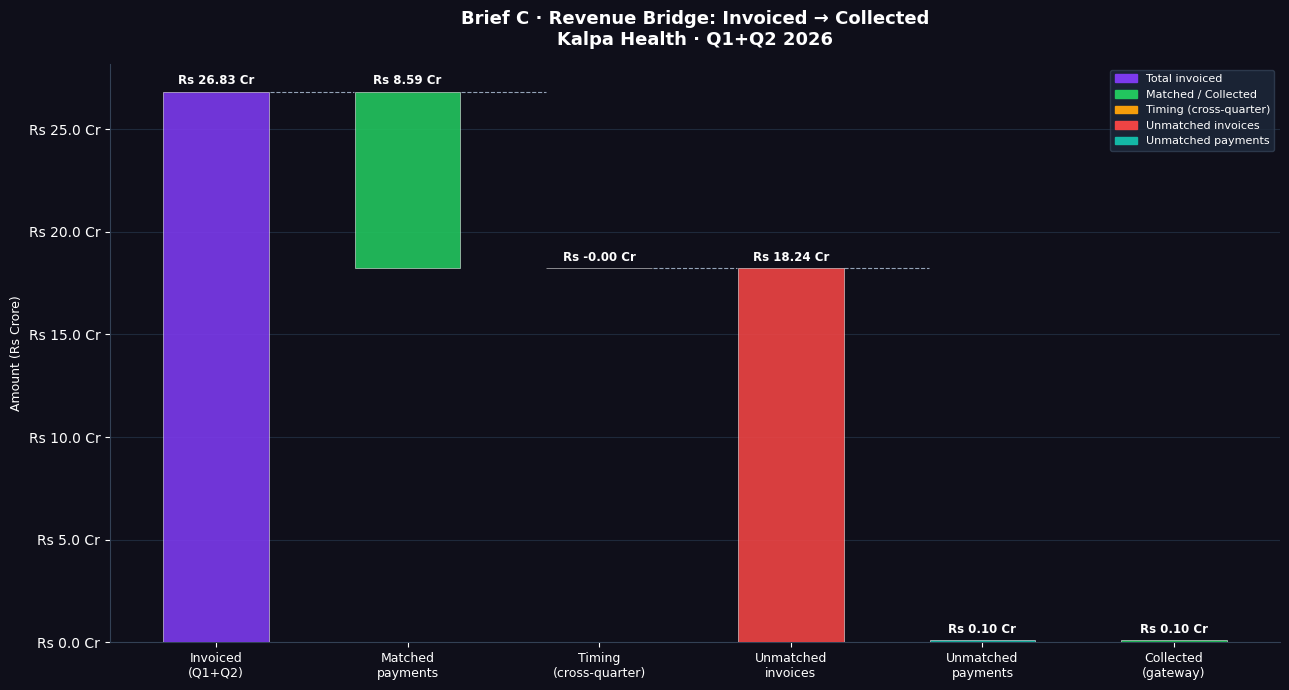

Bridge chart saved.


In [19]:
# Cell 11 · Bridge waterfall chart
fig, ax = plt.subplots(figsize=(13, 7))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)

labels = ['Invoiced\n(Q1+Q2)', 'Matched\npayments', 'Timing\n(cross-quarter)',
          'Unmatched\ninvoices', 'Unmatched\npayments', 'Collected\n(gateway)']
bar_vals   = [total_invoiced, -total_matched, -total_timing,
              -total_unmatched_inv, total_unmatched_pay, 0]
bar_colors = [PURPLE, GREEN, AMBER, RED, TEAL, GREEN]

running, bottoms, heights = 0, [], []
for i, v in enumerate(bar_vals):
    if i == 0:
        bottoms.append(0); heights.append(v); running = v
    elif i == len(bar_vals) - 1:
        bottoms.append(0); heights.append(running)
    else:
        if v < 0:
            bottoms.append(running + v); heights.append(-v)
        else:
            bottoms.append(running); heights.append(v)
        running += v

x = np.arange(len(labels))
bars = ax.bar(x, heights, bottom=bottoms, color=bar_colors, width=0.55,
              zorder=3, alpha=0.9, edgecolor='white', linewidth=0.4)

for bar, h, b in zip(bars, heights, bottoms):
    crore = h / 1e7
    ax.text(bar.get_x() + bar.get_width()/2, b + h + total_invoiced*0.008,
            f'Rs {crore:.2f} Cr', ha='center', va='bottom',
            fontsize=8.5, color='white', fontweight='bold')

for i in range(len(x)-2):
    top = bottoms[i] + heights[i]
    ax.plot([x[i]+0.28, x[i+1]-0.28], [top, top],
            color=LGRAY, lw=0.8, ls='--', zorder=2)

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'Rs {v/1e7:.1f} Cr'))
ax.set_xticks(x); ax.set_xticklabels(labels, color='white', fontsize=9)
ax.tick_params(colors='white')
for sp in ['bottom','left']: ax.spines[sp].set_color('#334155')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(axis='y', color='#1e293b', lw=0.8, zorder=0)
ax.set_title('Brief C · Revenue Bridge: Invoiced → Collected\nKalpa Health · Q1+Q2 2026',
             color='white', fontsize=13, fontweight='bold', pad=14)
ax.set_ylabel('Amount (Rs Crore)', color='white', fontsize=9)
patches = [mpatches.Patch(color=c, label=l) for c, l in [
    (PURPLE,'Total invoiced'),(GREEN,'Matched / Collected'),
    (AMBER,'Timing (cross-quarter)'),(RED,'Unmatched invoices'),(TEAL,'Unmatched payments')]]
ax.legend(handles=patches, loc='upper right',
          facecolor='#1e293b', edgecolor='#334155', labelcolor='white', fontsize=8)
plt.tight_layout()
plt.savefig(OUT/'bridge_chart.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show(); print('Bridge chart saved.')


---
## Inferential Statistics · Profiling & distributions


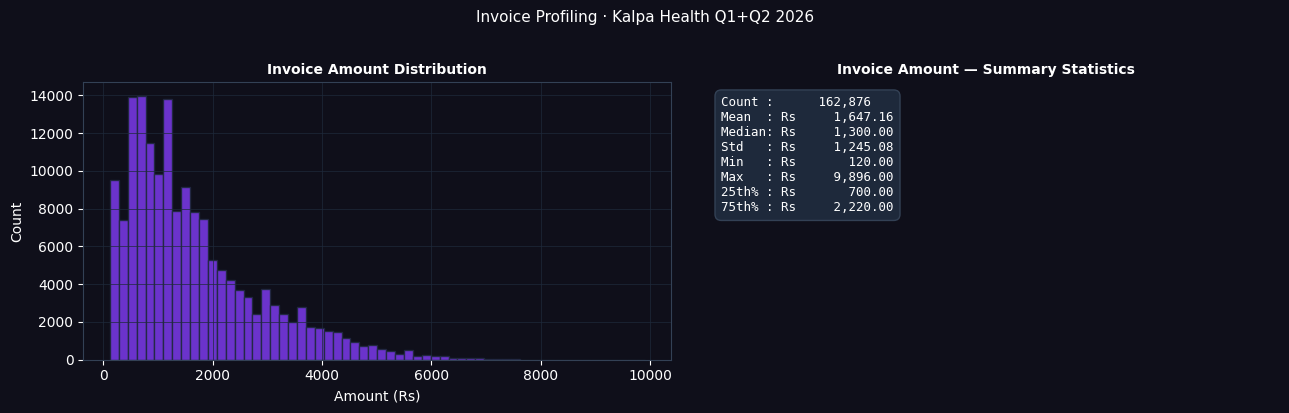

In [20]:
# Cell 12 · Invoice amount distribution + summary stats
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor(BG)
for ax in axes: ax.set_facecolor(BG)

axes[0].hist(inv_clean['amount'], bins=60, color=PURPLE, alpha=0.85, edgecolor='#1e293b')
axes[0].set_title('Invoice Amount Distribution', color='white', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Amount (Rs)', color='white'); axes[0].set_ylabel('Count', color='white')
axes[0].tick_params(colors='white')
for sp in axes[0].spines.values(): sp.set_color('#334155')
axes[0].grid(color='#1e293b', lw=0.5)

st = inv_clean['amount'].describe()
txt = (f"Count : {st['count']:>12,.0f}\n"
       f"Mean  : Rs {st['mean']:>12,.2f}\n"
       f"Median: Rs {inv_clean['amount'].median():>12,.2f}\n"
       f"Std   : Rs {st['std']:>12,.2f}\n"
       f"Min   : Rs {st['min']:>12,.2f}\n"
       f"Max   : Rs {st['max']:>12,.2f}\n"
       f"25th% : Rs {st['25%']:>12,.2f}\n"
       f"75th% : Rs {st['75%']:>12,.2f}")
axes[1].text(0.05, 0.95, txt, transform=axes[1].transAxes, va='top', ha='left',
             fontsize=9, fontfamily='monospace', color='white',
             bbox=dict(facecolor='#1e293b', edgecolor='#334155', boxstyle='round,pad=0.5'))
axes[1].set_title('Invoice Amount — Summary Statistics', color='white', fontsize=10, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Invoice Profiling · Kalpa Health Q1+Q2 2026', color='white', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUT/'invoice_distribution.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


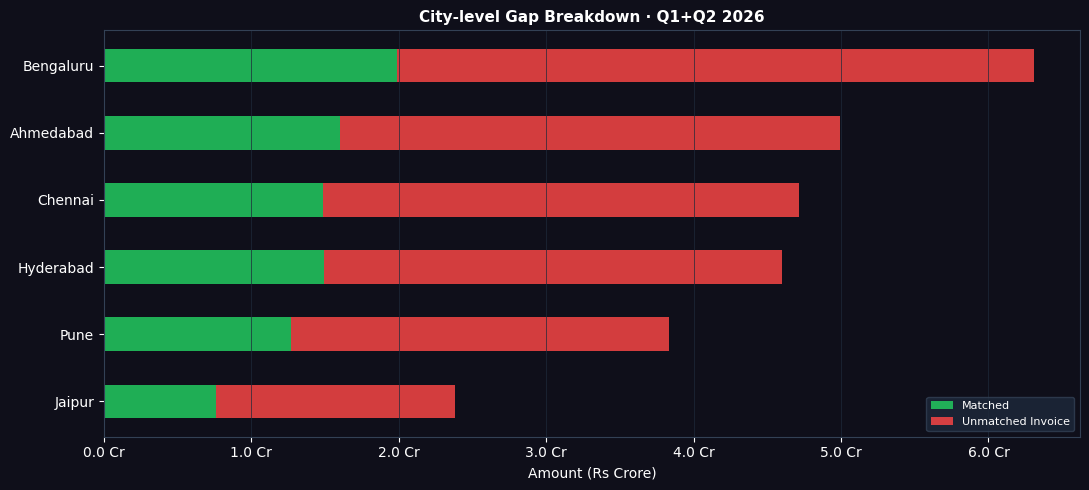

gap_category     matched  unmatched_invoice
city                                       
Jaipur         7576684.0         16234975.0
Pune          12674052.0         25658312.0
Hyderabad     14908273.0         31075285.0
Chennai       14854879.0         32282284.0
Ahmedabad     16018694.0         33943853.0
Bengaluru     19894305.0         43161577.0


In [21]:
# Cell 13 · City-level gap breakdown (stacked horizontal bar)
cat_colors = {'matched': GREEN, 'timing': AMBER, 'unmatched_invoice': RED}

city_pivot = (joined
              .groupby(['city','gap_category'])['amount'].sum()
              .unstack(fill_value=0)
              .assign(total=lambda d: d.sum(axis=1))
              .sort_values('total'))

fig, ax = plt.subplots(figsize=(11, 5))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
bottom = np.zeros(len(city_pivot))
for cat in ['matched','timing','unmatched_invoice']:
    if cat in city_pivot.columns:
        vals = city_pivot[cat].values / 1e7
        ax.barh(city_pivot.index, vals, left=bottom, color=cat_colors[cat],
                alpha=0.88, label=cat.replace('_',' ').title(), height=0.5)
        bottom += vals
ax.set_xlabel('Amount (Rs Crore)', color='white')
ax.set_title('City-level Gap Breakdown · Q1+Q2 2026', color='white', fontsize=11, fontweight='bold')
ax.tick_params(colors='white')
for sp in ax.spines.values(): sp.set_color('#334155')
ax.grid(axis='x', color='#1e293b', lw=0.5)
ax.legend(facecolor='#1e293b', edgecolor='#334155', labelcolor='white', fontsize=8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f'{v:.1f} Cr'))
plt.tight_layout()
plt.savefig(OUT/'city_gap_breakdown.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print(city_pivot.drop(columns='total').to_string())


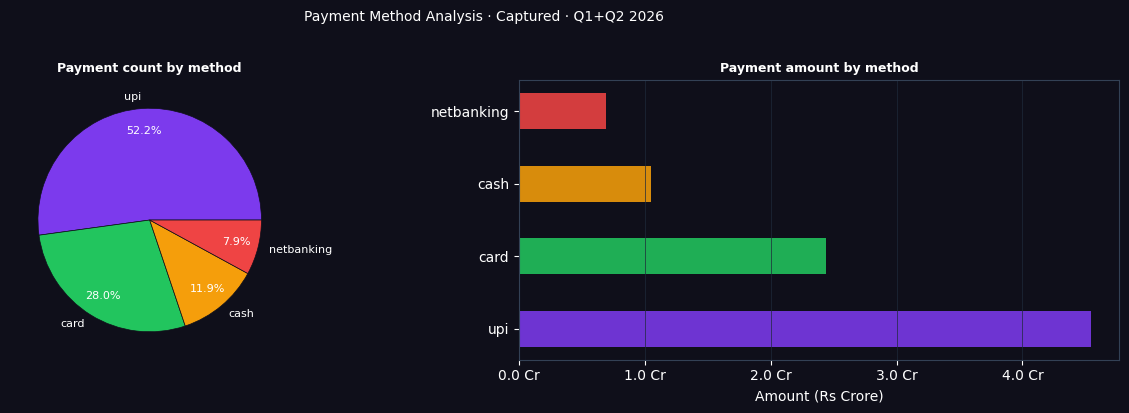

            count    total_rs
method                       
upi         27716  45434636.0
card        14865  24406788.0
cash         6325  10506356.0
netbanking   4220   6904134.0


In [22]:
# Cell 14 · Payment method breakdown
method_summary = (pay_captured
                  .groupby('method')
                  .agg(count=('payment_id','count'), total_rs=('amount_rs','sum'))
                  .sort_values('total_rs', ascending=False))

pal = [PURPLE, GREEN, AMBER, RED, TEAL, '#6366f1']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor(BG)
for ax in axes: ax.set_facecolor(BG)

axes[0].pie(method_summary['count'], labels=method_summary.index,
            colors=pal[:len(method_summary)], autopct='%1.1f%%', pctdistance=0.8,
            textprops={'color':'white','fontsize':8},
            wedgeprops={'linewidth':0.5,'edgecolor':BG})
axes[0].set_title('Payment count by method', color='white', fontsize=9, fontweight='bold')

axes[1].barh(method_summary.index, method_summary['total_rs']/1e7,
             color=pal[:len(method_summary)], alpha=0.88, height=0.5)
axes[1].set_xlabel('Amount (Rs Crore)', color='white')
axes[1].tick_params(colors='white')
axes[1].set_title('Payment amount by method', color='white', fontsize=9, fontweight='bold')
for sp in axes[1].spines.values(): sp.set_color('#334155')
axes[1].grid(axis='x', color='#1e293b', lw=0.5)
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f'{v:.1f} Cr'))
plt.suptitle('Payment Method Analysis · Captured · Q1+Q2 2026', color='white', fontsize=10, y=1.02)
plt.tight_layout()
plt.savefig(OUT/'payment_method_breakdown.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()
print(method_summary.to_string())


Quarter breakdown (Rs):
gap_category     matched  unmatched_invoice
quarter                                    
Q1            47961808.0         87474091.0
Q2            37965079.0         94882195.0


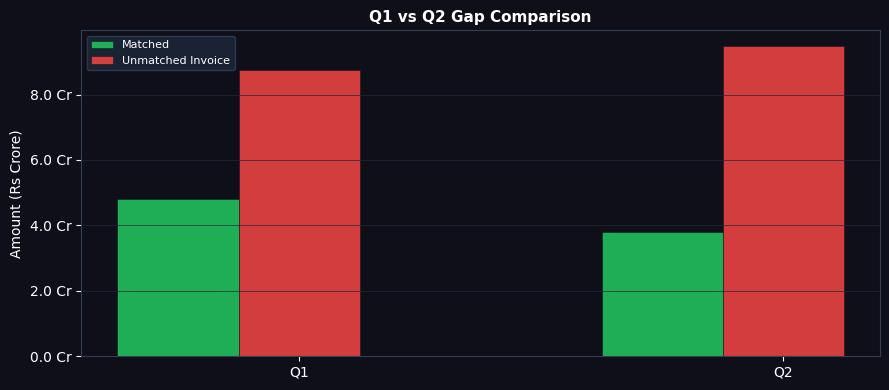

In [23]:
# Cell 15 · Q1 vs Q2 comparison
qtr_pivot = (joined
             .groupby(['quarter','gap_category'])['amount'].sum()
             .unstack(fill_value=0))
print('Quarter breakdown (Rs):')
print(qtr_pivot.to_string())

cats = [c for c in ['matched','timing','unmatched_invoice'] if c in qtr_pivot.columns]
x_pos = np.arange(len(qtr_pivot)); width = 0.25

fig, ax = plt.subplots(figsize=(9, 4))
fig.patch.set_facecolor(BG); ax.set_facecolor(BG)
for i, cat in enumerate(cats):
    ax.bar(x_pos + (i-1)*width, qtr_pivot[cat].values/1e7, width=width,
           color=cat_colors.get(cat, PURPLE), alpha=0.88,
           label=cat.replace('_',' ').title(), edgecolor=BG, linewidth=0.4)
ax.set_xticks(x_pos); ax.set_xticklabels(qtr_pivot.index, color='white')
ax.tick_params(colors='white'); ax.set_ylabel('Amount (Rs Crore)', color='white')
ax.set_title('Q1 vs Q2 Gap Comparison', color='white', fontsize=11, fontweight='bold')
for sp in ax.spines.values(): sp.set_color('#334155')
ax.grid(axis='y', color='#1e293b', lw=0.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v,_: f'{v:.1f} Cr'))
ax.legend(facecolor='#1e293b', edgecolor='#334155', labelcolor='white', fontsize=8)
plt.tight_layout()
plt.savefig(OUT/'q1_vs_q2_comparison.png', dpi=150, bbox_inches='tight', facecolor=BG)
plt.show()


In [24]:
# Cell 16 · Duplicate profile summary
print('═══ DUPLICATE PROFILE ═══')
print(f'Invoice duplicates : {len(inv_dups):,} rows  ({dup_inv} dropped)')
if len(inv_dups): print(inv_dups[['invoice_id','invoice_date','amount','city']].head())
print(f'\nPayment duplicates : {len(pay_dups):,} rows  ({dup_pay} dropped)')
if len(pay_dups): print(pay_dups[['payment_id','notes_invoice_ref','amount_paise']].head())
print(f'\nRejected payments (non-captured): {len(pay_rejected):,}')
print(pay_rejected['status'].value_counts().to_string())


═══ DUPLICATE PROFILE ═══
Invoice duplicates : 0 rows  (0 dropped)

Payment duplicates : 0 rows  (0 dropped)

Rejected payments (non-captured): 2,115
status
failed    2115


---
## Step 6 · Export clean files

| File | Contents |
|---|---|
| `invoices_clean.csv` | Deduplicated invoices with `gap_category` column |
| `payments_clean.csv` | Captured payments only, paise→Rs, normalised key |
| `unmatched_invoices.csv` | Finance action list: invoices with no captured payment |
| `unmatched_payments.csv` | Payments referencing no known invoice |
| `bridge_summary.csv` | Headline bridge numbers (one row per category) |


In [25]:
# Cell 17 · Export all clean files
inv_export = joined[['invoice_id','invoice_date','booking_id','patient_id',
                      'city','channel','amount','quarter','gap_category',
                      'total_paid_rs','payment_count','last_paid_at','methods']].copy()
inv_export.to_csv(OUT/'invoices_clean.csv', index=False)
print(f'invoices_clean.csv      : {len(inv_export):,} rows')

pay_export = pay_captured[['payment_id','notes_invoice_ref','inv_key',
                            'amount_rs','method','status','paid_at',
                            'settlement_id','quarter']].copy()
pay_export.to_csv(OUT/'payments_clean.csv', index=False)
print(f'payments_clean.csv      : {len(pay_export):,} rows')

unmatched_inv_exp = (joined[joined['gap_category']=='unmatched_invoice']
                     [['invoice_id','invoice_date','booking_id','patient_id',
                        'city','channel','amount','quarter']]
                     .sort_values('amount', ascending=False))
unmatched_inv_exp.to_csv(OUT/'unmatched_invoices.csv', index=False)
print(f'unmatched_invoices.csv  : {len(unmatched_inv_exp):,} rows  '
      f'Rs {unmatched_inv_exp["amount"].sum():,.2f}')

pay_unmatched.to_csv(OUT/'unmatched_payments.csv', index=False)
print(f'unmatched_payments.csv  : {len(pay_unmatched):,} rows  '
      f'Rs {pay_unmatched["total_paid_rs"].sum():,.2f}')

bridge_df = pd.DataFrame({
    'category'     : ['invoiced','matched','timing','unmatched_invoice','unmatched_payment','collected'],
    'invoice_count': [count_total_inv, count_matched, count_timing, count_unmatched_inv, count_unmatched_pay, None],
    'amount_rs'    : [total_invoiced, total_matched, total_timing, total_unmatched_inv, total_unmatched_pay, total_collected],
})
bridge_df.to_csv(OUT/'bridge_summary.csv', index=False)
print(f'bridge_summary.csv      : {len(bridge_df)} rows')
print('\nAll exports complete. Files saved to:', OUT)


invoices_clean.csv      : 162,876 rows
payments_clean.csv      : 53,126 rows
unmatched_invoices.csv  : 110,531 rows  Rs 182,356,286.00
unmatched_payments.csv  : 567 rows  Rs 970,827.00
bridge_summary.csv      : 6 rows

All exports complete. Files saved to: E:\IITGN_Projects\Week_3\build1-starter-kit\brief_c\data


In [26]:
# Cell 18 · Final one-sentence claim (Brief C answer)
timing_pct  = total_timing / total_invoiced * 100
gap_pct     = total_unmatched_inv / total_invoiced * 100
hard_gap    = total_unmatched_inv - total_unmatched_pay

print('═══ BRIEF C ANSWER ════════════════════════════════════════════════════')
print()
print(f'Of Rs {total_invoiced/1e7:.2f} Cr invoiced across Q1+Q2 2026,')
print(f'Rs {total_unmatched_inv/1e7:.2f} Cr ({gap_pct:.1f}%) sits in invoices with no captured payment;')
print(f'Rs {total_timing/1e7:.2f} Cr ({timing_pct:.1f}%) of that is timing across the quarter boundary;')
print(f'the hard unreconciled gap is Rs {hard_gap/1e7:.2f} Cr — the list finance needs to act on.')
print()
print('STEP 4 OPEN (what would make you wrong?):')
print('  1. Payments captured under a DIFFERENT invoice id (silent mis-match -> re-check ref normalisation).')
print('  2. Some "captured" payments later reversed outside this export window.')
print('  3. Gateway switched mid-quarter -> earlier payments exist in a second feed not yet included.')


═══ BRIEF C ANSWER ════════════════════════════════════════════════════

Of Rs 26.83 Cr invoiced across Q1+Q2 2026,
Rs 18.24 Cr (68.0%) sits in invoices with no captured payment;
Rs 0.00 Cr (0.0%) of that is timing across the quarter boundary;
the hard unreconciled gap is Rs 18.14 Cr — the list finance needs to act on.

STEP 4 OPEN (what would make you wrong?):
  1. Payments captured under a DIFFERENT invoice id (silent mis-match -> re-check ref normalisation).
  2. Some "captured" payments later reversed outside this export window.
  3. Gateway switched mid-quarter -> earlier payments exist in a second feed not yet included.
